# Calculate theoretical cold pool speed, plot planview
Loops through all wrfout files and computes 'c' as in Squitieri and Gallus, 2020. Each file is saved per timestamp

In [1]:
import wrf
from wrf import CoordPair, vertcross, get_cartopy, getvar, latlon_coords, to_np, destagger, ll_to_xy
import numpy as np
from netCDF4 import Dataset 
import matplotlib.pyplot as plt
import pyart
import geocat.viz as gv
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
import os
import glob
from metpy.units import units
import cartopy.crs as crs
import pandas as pd
import xarray as xr
import metpy 
import metpy.calc as mpcalc
import numpy.ma as ma
import matplotlib.ticker as mticker

import cartopy.feature as cfeature

import pkg_resources


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
# Set up for saving graphics files
path_out = '/glade/u/home/athornton/wrf_visualization/cold_pool_data/'

# Set directory where wrfout files reside, and list the files for processing.  Set up for a directory with only wrfout files.
os.chdir("/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1")
os.getcwd()

'/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1'

In [3]:
datafiles = (sorted(glob.glob("wrfout_d03*")))#17_00:00:00")))
numfiles=len(datafiles)
print(numfiles)
print(datafiles[23])

85
wrfout_d03_2018-08-25_17:30:00


In [4]:
input = "wrfout_d03_2018-08-25_23:30:00" 
ncfile = Dataset(input)
slp = getvar(ncfile, "slp")
lats, lons = latlon_coords(slp)
latnp = to_np(lats)
lonnp = to_np(lons)
cart_proj = get_cartopy(wrfin=ncfile)
print (cart_proj)
proj=crs.PlateCarree()

+proj=merc +a=6370000.0 +b=6370000.0 +nadgrids=@null +lon_0=0.0 +lat_ts=14.828 +k=1 +units=m +no_defs +type=crs


In [5]:
# Slice these arrays so they work with the new dataset
lat = to_np(lats)[:,0]
lon = to_np(lons)[0]

In [6]:
# define plotting function
def create_fig():
    fig = plt.figure(figsize=(12,12))
    plt.rcParams['savefig.dpi'] = 255

    proj=crs.PlateCarree()

    ax = plt.axes(projection=proj)
    ax.set_extent([-26, -4, 1, 24],crs.PlateCarree())
    #ax.add_feature(cfeature.STATES.with_scale('50m'), linewidth=.5, edgecolor="black")
    ax.add_feature(cfeature.COASTLINE.with_scale('10m'), linewidth=0.8, edgecolor='black')
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), linewidth=1.0)
    
    #gv.set_titles_and_labels(ax, lefttitle=" 600 hPa Zonal Winds", lefttitlefontsize=18)
    plt.title('Cold Pool Strength', loc='left', weight='bold', fontsize=18)
    plt.title(titletime, loc='right', fontsize=15)
    gl1 = ax.gridlines(crs=proj, linewidth=1, color='darkgray', draw_labels=True)
    gl1.top_labels = False
    gl1.right_labels = False
    gl1.xlocator = mticker.FixedLocator(np.arange(-90,40,2))
    gl1.ylocator = mticker.FixedLocator(np.arange(-11,14,2))
    gl1.xformatter = LongitudeFormatter(degree_symbol='')
    gl1.yformatter = LatitudeFormatter(degree_symbol='')

    levels = np.arange(0, 15, 0.1) ## c2
    #levels = np.arange(0.01, 3, 0.1) ## c2
    #levels = np.arange(-1, 0, 0.01)  ## B

    
    cf = plt.contourf(lonnp, latnp, c2,
                      levels=levels, extend='both',
                         cmap='PuBu', transform=proj)
    plt.tight_layout()
    cb = plt.colorbar(cf, ax=ax, orientation="horizontal", pad=.03, shrink=.6, aspect=30)
    cb.set_label('$C$ ($m/s$)', fontsize=14)
    
    outTPlotName= 'c_'+filetime+'.png'
    #plt.savefig(plotsdir+outTPlotName)

### For context, I have it set to one time stamp
see index

In [9]:
# index of time stamp
datafiles[50]

'wrfout_d03_2018-08-26_07:00:00'

In [10]:
# times = []
# c_list = []
for i in range(50, 51):
    wrf_out_data = xr.open_dataset(datafiles[i])  
    ncfile = Dataset(datafiles[i])
    Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
    timestr=(str(Time))
    # Set up one time string for plot titles, another for file names
    titletime=(timestr[0:10]+' '+timestr[11:16])
    filetime=(timestr[0:10]+'_'+timestr[11:16])
    print('WRF valid time: ',filetime)
    
    theta_pert = wrf_out_data['T'][0].metpy.quantify() # drop xtra dim and keep lowest levels
    qvapor = wrf_out_data['QVAPOR'][0].metpy.quantify()
    qcloud = wrf_out_data['QCLOUD'][0].metpy.quantify()
    qrain = wrf_out_data['QRAIN'][0].metpy.quantify()
    z = getvar(ncfile, 'z').metpy.quantify()
    
    theta_full = theta_pert + 300*units('K')    # add 300K for full theta
    
    theta_bar = theta_full.mean(dim='west_east')      # average along latitude to get ambient theta
    theta_p = theta_full-theta_bar
    qv_bar = qvapor.mean(dim='west_east')             # average along latitude to get ambient qvapor
    #theta_neg = theta_pert.where(theta_pert < 0)      # extract only negative theta perturbations
    
    B = metpy.constants.earth_gravity * (theta_pert/theta_bar + 0.61*(qvapor-qv_bar)-qrain-qcloud)
    coldpool_mask = (B < 0)
    B_masked = B.where(coldpool_mask)

    levels = z[:,0,0]
    deltaZ = (levels - levels.shift(bottom_top=-1))
    c2_value = ((B_masked.shift(bottom_top=-1)+B_masked)*.5*deltaZ).sum(dim='bottom_top') 
    c = np.sqrt(c2_value)    

    #f = create_fig()
    #plt.close()
    

WRF valid time:  2018-08-26_07:00


### Playing around with two different masking options to isolate the cold pool

In [11]:
## first option: based on Zipser ice-scattering signature
## Captures the whole cold pool and more. 
olr = wrf_out_data['OLR'][0]
olr_mask = olr < 225
c2 = c.where(olr_mask)

In [12]:
## second option: based on squitieri and gallus, 2020
## Captures strongest region of the cold pool
ncfile = Dataset(datafiles[i-1])
mdbz = getvar(ncfile, "mdbz")
rain_mask = mdbz > 35 
c2 = c.where(rain_mask)

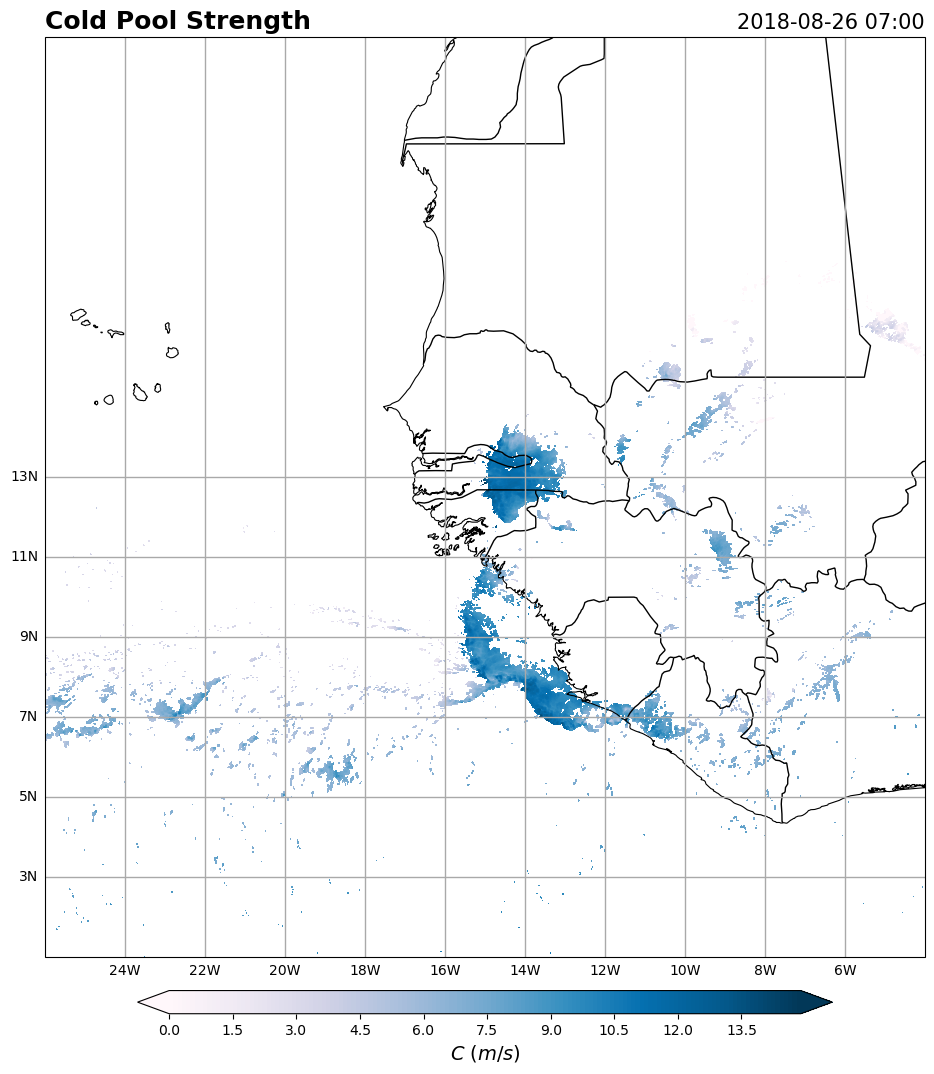

In [13]:
f = create_fig()

In [138]:
# c_array = np.array(c_list)

In [139]:
# Create one dataset with u, v winds at each lat, lon, time coordinate for this ensemble member
# ds = xr.Dataset( 
#     data_vars=dict(
#         c=(["time","lat","lon"], c_array.data),
#     ),
#     coords=dict(
#         time=("time", times),
#         lon=("lon", lon),
#         lat=("lat", lat),
#     ),
# )